# High-rate codes — logical error rate vs p

Two stacked panels: **(a)** hyperbolic Floquet codes (pymatching) and **(b)** stairway codes (Tesseract). Each curve is one `[[n, k, d]]` code at a fixed Z-bias `p_bell_z = BIAS · p`."""

In [23]:
import ast
import datetime
import glob
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sinter

In [24]:
BIAS = 10

HYPERBOLIC_R = 16
STAIRWAY_R = "d"

def _parse_custom_counts(s):
    if not isinstance(s, str) or s == 'Counter()':
        return {}
    m = re.search(r"Counter\(\{(.+)\}\)", s)
    if not m:
        return {}
    return {k: int(v) for k, v in re.findall(r"'(\w+)':\s*(\d+)", m.group(1))}


_NKD_FILE = re.compile(r'n=(\d+)_k=(\d+)_d=(\d+)')


def _nkd_from_meta(m):
    """Resolve (n, k, d): prefer sidecar metadata fields (stairway), fall back
    to parsing the input filename (hyperbolic)."""
    n = m.get('n')
    k = m.get('k')
    d = m.get('expected_distance', m.get('d'))
    if n is not None and k is not None and d is not None:
        return (int(n), int(k), int(d))
    mm = _NKD_FILE.search(m.get('input_circuit', ''))
    if not mm:
        return (None, None, None)
    return tuple(int(x) for x in mm.groups())


def load_collection(csv_glob, bias):
    files = sorted(glob.glob(csv_glob))
    if not files:
        raise FileNotFoundError(f'No files matched: {csv_glob}')

    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

    if 'custom_counts' in df.columns:
        counts = df['custom_counts'].apply(_parse_custom_counts)
        df['low_confidence_shots'] = counts.apply(
            lambda c: c.get('low_confidence_shots', 0)
        )
    else:
        df['low_confidence_shots'] = 0

    df = df.groupby('strong_id').agg({
        'shots': 'sum',
        'errors': 'sum',
        'discards': 'sum',
        'seconds': 'sum',
        'low_confidence_shots': 'sum',
        'decoder': 'first',
        'json_metadata': 'first',
    }).reset_index()

    meta = df['json_metadata'].apply(
        lambda s: ast.literal_eval(s) if isinstance(s, str) else dict(s)
    )
    df['p'] = meta.apply(lambda m: m.get('p'))
    df['p_bell_z'] = meta.apply(lambda m: m.get('p_bell_z'))
    df['bias'] = meta.apply(lambda m: m.get('bias'))

    df[['n', 'k', 'd']] = pd.DataFrame(
        meta.apply(_nkd_from_meta).tolist(), index=df.index,
    )
    df['code'] = df.apply(lambda r: f"[[{r['n']},{r['k']},{r['d']}]]", axis=1)

    available_biases = sorted(df['bias'].dropna().unique())
    df = df[np.isclose(df['bias'].astype(float), float(bias))].reset_index(drop=True)
    if df.empty:
        raise ValueError(
            f'no rows for BIAS={bias} in {csv_glob}; '
            f'available biases: {available_biases}'
        )

    code_order = (
        df.drop_duplicates('code').sort_values('n')['code'].tolist()
    )
    return df, code_order


df_hyp, codes_hyp = load_collection(
    '../out/collection/threshold_hyperbolic_floquet,*.csv', BIAS,
)
df_st, codes_st = load_collection(
    '../out/collection/threshold_stairway,*.csv', BIAS,
)

print(f'hyperbolic: {len(df_hyp)} rows, codes={codes_hyp}')
print(f'stairway:   {len(df_st)} rows, codes={codes_st}')
print(
    f'stairway low-confidence shots: '
    f'{int(df_st["low_confidence_shots"].sum())} / {int(df_st["shots"].sum())}'
)

hyperbolic: 96 rows, codes=['[[64,10,2]]', '[[256,10,4]]', '[[576,10,6]]', '[[1024,10,8]]', '[[1600,10,10]]', '[[2304,10,12]]']
stairway:   24 rows, codes=['[[192,16,4]]', '[[192,6,9]]', '[[288,14,10]]']
stairway low-confidence shots: 1306 / 1172596


Saved ../out/figures/20260625_high_rate_bias10.pdf


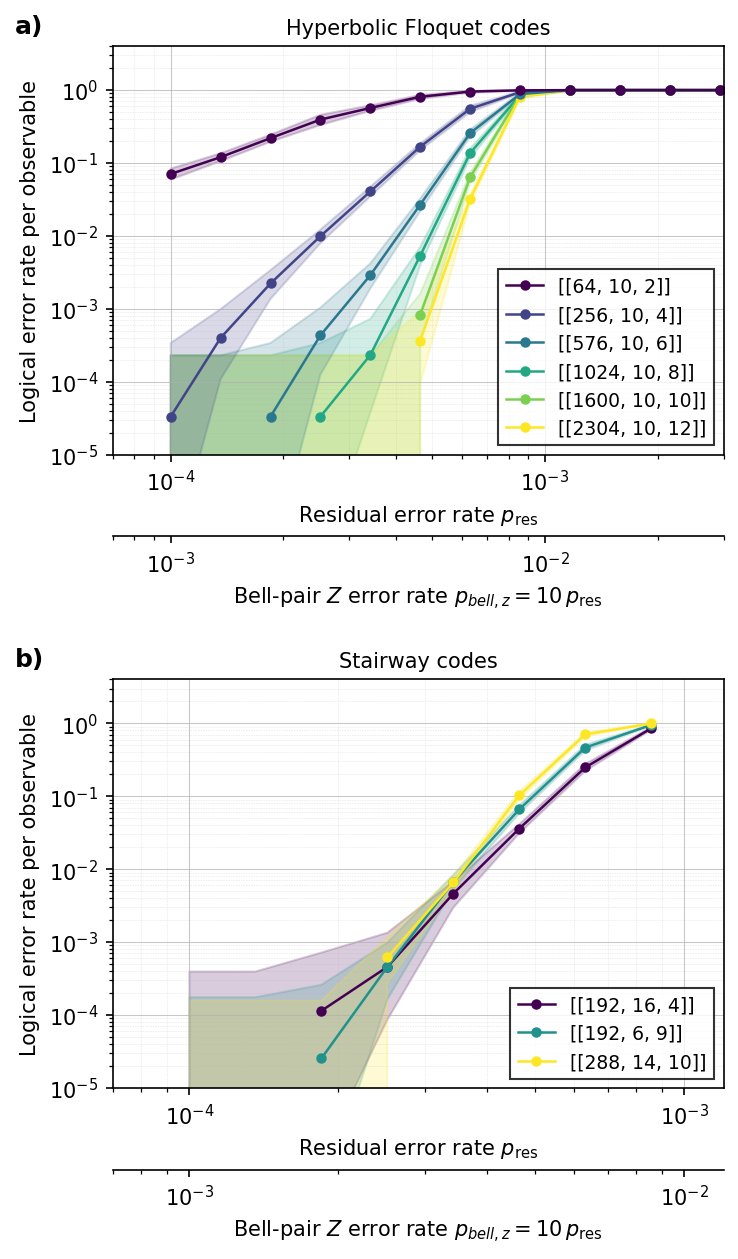

In [25]:
plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
})


def _df_to_tasks(df):
    tasks = []
    for _, row in df.iterrows():
        m = (ast.literal_eval(row['json_metadata'])
             if isinstance(row['json_metadata'], str)
             else dict(row['json_metadata']))
        m['n'] = int(row['n'])
        m['k'] = int(row['k'])
        m['expected_distance'] = int(row['d'])
        tasks.append(sinter.TaskStats(
            strong_id=row['strong_id'],
            decoder=row['decoder'],
            json_metadata=m,
            shots=int(row['shots']),
            errors=int(row['errors']),
            discards=int(row['discards']),
            seconds=float(row['seconds']),
        ))
    return tasks


def plot_panel(ax, df, code_order, label_suffix):
    """Draw one [[n,k,d]] family on `ax` with viridis colors, sorted legend,
    minor+major grid, and a secondary p_bell_z axis below."""
    cmap = plt.get_cmap('viridis')
    colors = {
        code: cmap(i / max(1, len(code_order) - 1))
        for i, code in enumerate(code_order)
    }

    def group_func(stat):
        n = stat.json_metadata['n']
        k = stat.json_metadata['k']
        d = stat.json_metadata['expected_distance']
        base = f'[[{n}, {k}, {d}]]'
        return f'{base} {label_suffix}' if label_suffix else base

    def plot_args_func(index, group_key, group_stats):
        # `code_order` keys have no spaces / no suffix — strip both.
        key = group_key.split(']]')[0].replace(' ', '') + ']]'
        return {
            'color': colors.get(key, 'k'),
            'marker': 'o', 'markersize': 4, 'linewidth': 1.2,
        }

    sinter.plot_error_rate(
        ax=ax,
        stats=_df_to_tasks(df),
        x_func=lambda s: s.json_metadata['p'],
        group_func=group_func,
        plot_args_func=plot_args_func,
        failure_units_per_shot_func=lambda s: 1 if s.decoder == 'pymatching' else s.json_metadata['expected_distance']/16,
        failure_values_func=lambda s: s.json_metadata['k'],
    )
    ax.loglog()

    handles, labels = ax.get_legend_handles_labels()
    def _extract_n(lbl):
        m = re.search(r'\[\[(\d+),', lbl)
        return int(m.group(1)) if m else 0
    pairs = sorted(zip(handles, labels), key=lambda hl: _extract_n(hl[1]))
    if pairs:
        h, l = zip(*pairs)
        ax.legend(h, l, loc='lower right',
                  frameon=True, edgecolor='black', fancybox=False)

    ax.set_ylim(1e-5, 4)
    ax.set_xlabel(r'Residual error rate $p_{\text{res}}$')
    ax.set_ylabel(r'Logical error rate per observable')
    ax.grid(which='major', linestyle='-', linewidth=0.5, alpha=0.7)
    ax.grid(which='minor', linestyle=':', linewidth=0.3, alpha=0.5)


fig, (ax_hyp, ax_st) = plt.subplots(2, 1, figsize=(5, 8))

plot_panel(ax_hyp, df_hyp, codes_hyp, label_suffix='')
ax_hyp.set_title('Hyperbolic Floquet codes')
ax_hyp.set_xlim(float(df_hyp['p'].min()) * 0.7, 3e-3)

plot_panel(ax_st, df_st, codes_st, label_suffix='')
ax_st.set_title('Stairway codes')
ax_st.set_xlim(float(df_st['p'].min()) * 0.7, float(df_st['p'].max()) * 1.4)

# Panel labels (a) / (b) at top-left of each axes.
for ax, tag in [(ax_hyp, 'a)'), (ax_st, 'b)')]:
    ax.text(
        -0.16, 1.02, tag,
        transform=ax.transAxes, fontsize=12, fontweight='bold',
        va='bottom', ha='left',
    )

# Reserve space for the secondary p_bell_z axes under each panel before
# attaching them, so tight_layout doesn't have to retro-fit anything.
fig.tight_layout()
fig.subplots_adjust(hspace=0.55)

for ax in (ax_hyp, ax_st):
    ax_pbz = ax.secondary_xaxis(
        -0.20,
        functions=(lambda p: p * BIAS, lambda pbz: pbz / BIAS),
    )
    ax_pbz.set_xlabel(rf'Bell-pair $Z$ error rate $p_{{bell,z}} = {BIAS:g}\,p_{{\text{{res}}}}$')

fig.set_dpi(150)

out_dir = Path('../out/figures')
out_dir.mkdir(parents=True, exist_ok=True)
date = datetime.date.today().strftime('%Y%m%d')
out_path = out_dir / f'{date}_high_rate_bias{int(BIAS)}.pdf'
fig.savefig(out_path, bbox_inches='tight')
print(f'Saved {out_path}')
plt.show()

In [19]:
df_st

,strong_id,shots,errors,discards,seconds,low_confidence_shots,decoder,json_metadata,p,p_bell_z,bias,n,k,d,code
0,03a2f539faef6a9000234556da484601c860733e9f31c0...,10000,0,0,869.249625,0,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.000100,0.001000,10.0,288,14,10,"[[288,14,10]]"
1,07d26e80790b46a0581da01a7716be6db16a2afa9b202e...,301,109,0,2463.253894,0,tesseract_short,"{'p': 0.0008576958985908946, 'rounds': -1, 'no...",0.000858,0.008577,10.0,192,16,4,"[[192,16,4]]"
2,0c3b5a0bdc1e2def227b041dd21bee21df609f81a7d6c0...,10000,0,0,207.582136,0,tesseract_short,"{'p': 0.00013593563908785255, 'rounds': -1, 'n...",0.000136,0.001359,10.0,192,16,4,"[[192,16,4]]"
3,1aa064dd167b498dfcb2e10fb0e3bedcdb54846739f7cf...,10000,0,0,2824.371529,0,tesseract_short,"{'p': 0.00018478497974222906, 'rounds': -1, 'n...",0.000185,0.001848,10.0,288,14,10,"[[288,14,10]]"
4,22bd889e4e916656cedbd809dcc588f1191be40c8a6bec...,10000,14,0,1766.863337,0,tesseract_short,"{'p': 0.0003414548873833601, 'rounds': -1, 'no...",0.000341,0.003415,10.0,192,16,4,"[[192,16,4]]"
5,264316f3da1c6178f2ecc70317cd347f7739dac6e848b4...,10000,87,0,6599.723858,0,tesseract_short,"{'p': 0.00046415888336127773, 'rounds': -1, 'n...",0.000464,0.004642,10.0,192,16,4,"[[192,16,4]]"
6,2a4d28be162737858bc835b41c76f5363be9239b3bf1c0...,10000,7,0,6603.269614,0,tesseract_short,"{'p': 0.00025118864315095795, 'rounds': -1, 'n...",0.000251,0.002512,10.0,288,14,10,"[[288,14,10]]"
7,331550d4de1d75c3e644c2d6cf15ce17d98cb154657d01...,10000,0,0,1431.559019,0,tesseract_short,"{'p': 0.00013593563908785255, 'rounds': -1, 'n...",0.000136,0.001359,10.0,288,14,10,"[[288,14,10]]"
8,3c0aa9e547eb3930f053d21cad94cc10e05cffb9581eb4...,387,115,0,4870.389887,10,tesseract_short,"{'p': 0.000630957344480193, 'rounds': -1, 'noi...",0.000631,0.006310,10.0,192,6,9,"[[192,6,9]]"
9,44ba3931f23808f140c3b83a5d83c3c44ea91f63d350ec...,10000,2,0,3948.099342,0,tesseract_short,"{'p': 0.00025118864315095795, 'rounds': -1, 'n...",0.000251,0.002512,10.0,192,6,9,"[[192,6,9]]"
